**Disusun oleh:**
1. Astriana Safira Maharsi (I0324003)
2. Leirisa Yajna Kirana Fagan (I0324015)

# Analisis Prediksi Efisiensi Energi Kendaraan Listrik                              Menggunakan Multiple Linear Regression

# 1. Data Cleaning dan Pemeriksaan Kualitas Data

## 1.1 Pemeriksaan Awal Dataset

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/leirisayajnakirana/Tugas-Besar-Analitika-Data/refs/heads/main/EV%20Energy%20Efficiency%20Dataset.csv"
df = pd.read_csv(url)

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (1197, 7)


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
0,2012,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
1,2012,Nissan,LEAF,Mid-size,80,7.0,4.739336
2,2013,Ford,Focus Electric,Compact,107,4.0,5.000000
3,2013,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
4,2013,Nissan,LEAF,Mid-size,80,7.0,4.739336


In [5]:

import pandas as pd
from IPython.display import display

# ==================================================
# 1. MEMBACA DATASET
# ==================================================
import pandas as pd
from IPython.display import display

url = "https://raw.githubusercontent.com/leirisayajnakirana/Tugas-Besar-Analitika-Data/refs/heads/main/EV%20Energy%20Efficiency%20Dataset.csv"
df = pd.read_csv(url)

print("Dataset berhasil dibaca!")


# ==================================================
# 2. UKURAN DATASET
# ==================================================
tabel_ukuran = pd.DataFrame({
    "Informasi": ["Jumlah baris", "Jumlah kolom"],
    "Nilai": [df.shape[0], df.shape[1]]
})

print("1. UKURAN DATASET")
display(tabel_ukuran.style.hide(axis="index"))


# ==================================================
# 3. NAMA DAN TIPE DATA KOLOM
# ==================================================
tabel_kolom = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Tipe Data": df.dtypes.astype(str).values
})

print("2. NAMA DAN TIPE DATA KOLOM")
display(tabel_kolom.style.hide(axis="index"))


# ==================================================
# 4. CONTOH DATA
# ==================================================
print("3. CONTOH DATA")
display(df.head().style.hide(axis="index"))


# ==================================================
# 5. INFORMASI DATASET
# ==================================================
tabel_info = pd.DataFrame({
    "Kolom": df.columns,
    "Jumlah Data Terisi": df.notnull().sum().values,
    "Jumlah Missing Values": df.isnull().sum().values,
    "Tipe Data": df.dtypes.astype(str).values
})

print("4. INFORMASI DATASET")
display(tabel_info.style.hide(axis="index"))


# ==================================================
# 6. PEMERIKSAAN MISSING VALUES
# ==================================================
tabel_missing = pd.DataFrame({
    "Kolom": df.columns,
    "Jumlah Missing Values": df.isnull().sum().values,
    "Persentase Missing Values (%)": (
        df.isnull().mean().values * 100
    ).round(2)
})

print("5. PEMERIKSAAN MISSING VALUES")
display(tabel_missing.style.hide(axis="index"))


# ==================================================
# 7. PEMERIKSAAN DUPLIKASI
# ==================================================
jumlah_duplikat = df.duplicated().sum()

tabel_duplikat = pd.DataFrame({
    "Aspek Pemeriksaan": ["Baris duplikat"],
    "Jumlah": [int(jumlah_duplikat)],
    "Status": [
        "Tidak ada duplikat"
        if jumlah_duplikat == 0
        else "Terdapat duplikat"
    ]
})

print("6. PEMERIKSAAN DUPLIKASI")
display(tabel_duplikat.style.hide(axis="index"))


# ==================================================
# 8. STATISTIK DESKRIPTIF
# ==================================================
print("7. STATISTIK DESKRIPTIF")
display(df.describe().T.style.hide(axis="index"))


# ==================================================
# 9. PEMERIKSAAN SPASI SEBELUM CLEANING
# ==================================================
kolom_kategori = ["Make", "Model", "Vehicle class"]

hasil_spasi = []

for kolom in kolom_kategori:
    jumlah_spasi = (
        df[kolom].astype("string")
        .ne(df[kolom].astype("string").str.strip())
    ).sum()

    hasil_spasi.append({
        "Kolom": kolom,
        "Jumlah Spasi Berlebih": int(jumlah_spasi),
        "Status": (
            "Tidak ditemukan"
            if jumlah_spasi == 0
            else "Ditemukan"
        )
    })

print("8. PEMERIKSAAN SPASI SEBELUM CLEANING")
display(pd.DataFrame(hasil_spasi).style.hide(axis="index"))


# ==================================================
# 10. PEMERIKSAAN VALIDITAS NILAI NUMERIK
# ==================================================
hasil_validasi = [
    {
        "Aspek Pemeriksaan":
            "Tahun model di luar rentang 2012–2026",
        "Jumlah": int(
            (~df["Model year"].between(2012, 2026)).sum()
        )
    },
    {
        "Aspek Pemeriksaan": "Daya motor <= 0",
        "Jumlah": int(
            (df["Motor (kW)"] <= 0).sum()
        )
    },
    {
        "Aspek Pemeriksaan": "Waktu pengisian <= 0",
        "Jumlah": int(
            (df["Recharge time (h)"] <= 0).sum()
        )
    },
    {
        "Aspek Pemeriksaan": "Efisiensi energi <= 0",
        "Jumlah": int(
            (df["Energy Efficiency (km/kWh)"] <= 0).sum()
        )
    }
]

tabel_validasi = pd.DataFrame(hasil_validasi)

tabel_validasi["Status"] = tabel_validasi["Jumlah"].apply(
    lambda x: "Tidak ditemukan"
    if x == 0
    else "Perlu diperiksa"
)

print("9. PEMERIKSAAN VALIDITAS NILAI NUMERIK")
display(tabel_validasi.style.hide(axis="index"))


# ==================================================
# 11. PEMERIKSAAN KANDIDAT PENCAILAN DENGAN IQR
# ==================================================
kolom_numerik = [
    "Motor (kW)",
    "Recharge time (h)",
    "Energy Efficiency (km/kWh)"
]

hasil_iqr = []

for kolom in kolom_numerik:
    Q1 = df[kolom].quantile(0.25)
    Q3 = df[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    kondisi_pencilan = (
        (df[kolom] < batas_bawah) |
        (df[kolom] > batas_atas)
    )

    jumlah_pencilan = kondisi_pencilan.sum()

    hasil_iqr.append({
        "Variabel": kolom,
        "Q1": round(Q1, 2),
        "Q3": round(Q3, 2),
        "IQR": round(IQR, 2),
        "Batas Bawah": round(batas_bawah, 2),
        "Batas Atas": round(batas_atas, 2),
        "Jumlah Kandidat Pencilan": int(jumlah_pencilan)
    })

print("10. PEMERIKSAAN KANDIDAT PENCAILAN (IQR)")
display(pd.DataFrame(hasil_iqr).style.hide(axis="index"))


Dataset berhasil dibaca!
1. UKURAN DATASET


Informasi,Nilai
Jumlah baris,1197
Jumlah kolom,7


2. NAMA DAN TIPE DATA KOLOM


Nama Kolom,Tipe Data
Model year,int64
Make,object
Model,object
Vehicle class,object
Motor (kW),int64
Recharge time (h),float64
Energy Efficiency (km/kWh),float64


3. CONTOH DATA


...

Kolom,Jumlah Spasi Berlebih,Status
Make,14,Ditemukan
Model,11,Ditemukan
Vehicle class,0,Tidak ditemukan


9. PEMERIKSAAN VALIDITAS NILAI NUMERIK


Aspek Pemeriksaan,Jumlah,Status
Tahun model di luar rentang 2012–2026,0,Tidak ditemukan
Daya motor <= 0,0,Tidak ditemukan
Waktu pengisian <= 0,0,Tidak ditemukan
Efisiensi energi <= 0,0,Tidak ditemukan


10. PEMERIKSAAN KANDIDAT PENCAILAN (IQR)


Variabel,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Kandidat Pencilan
Motor (kW),230.000000,420.000000,190.000000,-55.000000,705.000000,29
Recharge time (h),8.500000,12.000000,3.500000,3.250000,17.250000,16
Energy Efficiency (km/kWh),3.790000,5.100000,1.310000,1.820000,7.070000,0


## 1.2 Pemeriksaan Spasi pada Data Kategorikal

In [14]:

import pandas as pd
from IPython.display import display

# 1. MEMBACA DATASET DARI GITHUB
url = "https://raw.githubusercontent.com/leirisayajnakirana/Tugas-Besar-Analitika-Data/refs/heads/main/EV%20Energy%20Efficiency%20Dataset.csv"
df = pd.read_csv(url)


# 2. MEMBUAT SALINAN DATASET
df_clean = df.copy()

# 3. MEMBERSIHKAN SPASI PADA DATA KATEGORIKAL
kolom_kategori = ["Make", "Model", "Vehicle class"]

for kolom in kolom_kategori:
    df_clean[kolom] = df_clean[kolom].str.strip()


# TABEL 1: PEMERIKSAAN SPASI
hasil_spasi = []

for kolom in kolom_kategori:
    jumlah_spasi = (
        df_clean[kolom] != df_clean[kolom].str.strip()
    ).sum()

    hasil_spasi.append({
        "Kolom": kolom,
        "Jumlah Spasi Berlebih": int(jumlah_spasi),
        "Status": "Bersih" if jumlah_spasi == 0
        else "Perlu diperiksa"
    })

print("1. PEMERIKSAAN SPASI")
display(pd.DataFrame(hasil_spasi).style.hide(axis="index"))


# TABEL 2: PEMERIKSAAN MISSING VALUES
tabel_missing = pd.DataFrame({
    "Kolom": df_clean.columns,
    "Jumlah Missing Values": df_clean.isnull().sum().values,
    "Status": [
        "Lengkap" if jumlah == 0 else "Terdapat nilai kosong"
        for jumlah in df_clean.isnull().sum().values
    ]
})

print("2. PEMERIKSAAN MISSING VALUES")
display(tabel_missing.style.hide(axis="index"))


# TABEL 3: PEMERIKSAAN DUPLIKASI
jumlah_duplikat = df_clean.duplicated().sum()

tabel_duplikat = pd.DataFrame({
    "Aspek Pemeriksaan": ["Duplikasi seluruh baris"],
    "Jumlah": [int(jumlah_duplikat)],
    "Status": [
        "Tidak ada duplikat" if jumlah_duplikat == 0
        else "Terdapat duplikat"
    ]
})

print("3. PEMERIKSAAN DUPLIKASI")
display(tabel_duplikat.style.hide(axis="index"))


# TABEL 4: VALIDASI NILAI NUMERIK
hasil_numerik = [
    {
        "Aspek Pemeriksaan": "Tahun kendaraan di luar rentang (2012–2026)",
        "Jumlah": int((
            (df_clean["Model year"] < 2012) |
            (df_clean["Model year"] > 2026)
        ).sum())
    },
    {
        "Aspek Pemeriksaan": "Daya motor <= 0",
        "Jumlah": int((df_clean["Motor (kW)"] <= 0).sum())
    },
    {
        "Aspek Pemeriksaan": "Waktu pengisian <= 0",
        "Jumlah": int((df_clean["Recharge time (h)"] <= 0).sum())
    },
    {
        "Aspek Pemeriksaan": "Efisiensi energi <= 0",
        "Jumlah": int((
            df_clean["Energy Efficiency (km/kWh)"] <= 0
        ).sum())
    }
]

tabel_numerik = pd.DataFrame(hasil_numerik)
tabel_numerik["Status"] = tabel_numerik["Jumlah"].apply(
    lambda x: "Valid" if x == 0 else "Perlu diperiksa"
)

print("4. VALIDASI NILAI NUMERIK")
display(tabel_numerik.style.hide(axis="index"))


# TABEL 5: UKURAN DATASET
tabel_ukuran = pd.DataFrame({
    "Informasi": ["Jumlah baris", "Jumlah kolom"],
    "Nilai": [df_clean.shape[0], df_clean.shape[1]]
})

print("5. UKURAN DATASET")
display(tabel_ukuran.style.hide(axis="index"))


# 6. MENAMPILKAN LIMA BARIS PERTAMA
print("6. CONTOH DATA SETELAH CLEANING")
display(df_clean.head().style.hide(axis="index"))


# 7. MENYIMPAN DATASET HASIL CLEANING
import pandas as pd

url_clean = "https://raw.githubusercontent.com/leirisayajnakirana/Tugas-Besar-Analitika-Data/main/ev_energy_efficiency_clean.csv"

df_clean = pd.read_csv(url_clean)

print("Ukuran dataset:", df_clean.shape)
display(df_clean.head())

print("Dataset hasil cleaning berhasil disimpan.")

print("Dataset final berhasil disimpan.")
print("Ukuran dataset final:", df_clean.shape)


1. PEMERIKSAAN SPASI


Kolom,Jumlah Spasi Berlebih,Status
Make,0,Bersih
Model,0,Bersih
Vehicle class,0,Bersih


2. PEMERIKSAAN MISSING VALUES


Kolom,Jumlah Missing Values,Status
Model year,0,Lengkap
Make,0,Lengkap
Model,0,Lengkap
Vehicle class,0,Lengkap
Motor (kW),0,Lengkap
Recharge time (h),0,Lengkap
Energy Efficiency (km/kWh),0,Lengkap


3. PEMERIKSAAN DUPLIKASI


...

6. CONTOH DATA SETELAH CLEANING


Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
2012,Mitsubishi,i-MiEV,Subcompact,49,7.000000,5.347594
2012,Nissan,LEAF,Mid-size,80,7.000000,4.739336
2013,Ford,Focus Electric,Compact,107,4.000000,5.000000
2013,Mitsubishi,i-MiEV,Subcompact,49,7.000000,5.347594
2013,Nissan,LEAF,Mid-size,80,7.000000,4.739336


Ukuran dataset: (1197, 7)


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
0,2012,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
1,2012,Nissan,LEAF,Mid-size,80,7.0,4.739336
2,2013,Ford,Focus Electric,Compact,107,4.0,5.000000
3,2013,Mitsubishi,i-MiEV,Subcompact,49,7.0,5.347594
4,2013,Nissan,LEAF,Mid-size,80,7.0,4.739336


Dataset hasil cleaning berhasil disimpan.
Dataset final berhasil disimpan.
Ukuran dataset final: (1197, 7)


## 1.3 Identifikasi Kandidat Pencilan

In [11]:
# MELIHAT NILAI KANDIDAT PENCILAN

for kolom in ["Motor (kW)", "Recharge time (h)"]:
    Q1 = df_clean[kolom].quantile(0.25)
    Q3 = df_clean[kolom].quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    pencilan = df_clean.loc[
        (df_clean[kolom] < batas_bawah) |
        (df_clean[kolom] > batas_atas),
        kolom
    ]

    print(f"\nKandidat pencilan pada {kolom}:")
    print(pencilan.sort_values().to_list())


Kandidat pencilan pada Motor (kW):
[750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 750, 764, 764, 764, 764, 764, 764, 783, 829, 829, 930, 930]

Kandidat pencilan pada Recharge time (h):
[3.0, 3.0, 3.0, 3.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.6, 18.6, 18.6, 18.6, 18.6, 18.6]


## 1.4 Pemeriksaan Kendaraan dengan Nilai Ekstrem

In [12]:

from IPython.display import display

# Kolom yang akan ditampilkan
kolom_tampil = [
    "Model year", "Make", "Model", "Vehicle class",
    "Motor (kW)", "Recharge time (h)",
    "Energy Efficiency (km/kWh)"
]

# 1. Kendaraan dengan daya motor tinggi
print("1. KENDARAAN DENGAN DAYA MOTOR >= 750 kW")

tabel_motor_tinggi = (
    df_clean.loc[
        df_clean["Motor (kW)"] >= 750,
        kolom_tampil
    ]
    .sort_values("Motor (kW)")
    .reset_index(drop=True)
)

display(tabel_motor_tinggi.style.hide(axis="index"))


# 2. Kendaraan dengan waktu pengisian ekstrem
print("2. KENDARAAN DENGAN WAKTU PENGISIAN <= 3 JAM ATAU >= 18 JAM")

tabel_waktu_ekstrem = (
    df_clean.loc[
        (df_clean["Recharge time (h)"] <= 3) |
        (df_clean["Recharge time (h)"] >= 18),
        kolom_tampil
    ]
    .sort_values("Recharge time (h)")
    .reset_index(drop=True)
)

display(tabel_waktu_ekstrem.style.hide(axis="index"))


1. KENDARAAN DENGAN DAYA MOTOR >= 750 kW


Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
2021,Tesla,"Model S Plaid (19"" Wheels)",Full-size,750,15.000000,5.524862
2021,Tesla,"Model S Plaid (21"" Wheels)",Full-size,750,15.000000,4.807692
2022,Tesla,"Model S Plaid (21"" Wheels)",Full-size,750,15.000000,4.807692
2022,Tesla,"Model S Plaid (19"" Wheels)",Full-size,750,15.000000,5.524862
2022,Tesla,"Model X Plaid (20"" Wheels)",Sport utility vehicle: Standard,750,14.000000,4.672897
2022,Tesla,"Model X Plaid (22"" Wheels)",Sport utility vehicle: Standard,750,14.000000,4.366812
2023,Tesla,"Model S Plaid (21"" Wheels)",Full-size,750,15.000000,4.807692
2023,Tesla,"Model S Plaid (19"" Wheels)",Full-size,750,15.000000,5.524862
2024,Tesla,"Model S Plaid (21"" Wheels)",Full-size,750,15.000000,4.566210
2024,Tesla,"Model S Plaid (19"" Wheels)",Full-size,750,15.000000,5.102041


2. KENDARAAN DENGAN WAKTU PENGISIAN <= 3 JAM ATAU >= 18 JAM


Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
2018,smart,fortwo electric drive cabriolet,Two-seater,60,3.000000,4.830918
2018,smart,fortwo electric drive coupe,Two-seater,60,3.000000,5.181347
2019,smart EQ,fortwo cabriolet,Two-seater,60,3.000000,4.830918
2019,smart EQ,fortwo coupe,Two-seater,60,3.000000,5.181347
2023,Fisker,Ocean Extreme/One,Sport utility vehicle: Standard,350,18.000000,4.366812
2023,Fisker,Ocean Ultra,Sport utility vehicle: Standard,350,18.000000,4.255319
2024,Fisker,"Ocean Extreme (20"" Wheels)",Sport utility vehicle: Standard,414,18.000000,4.366812
2024,Fisker,"Ocean Extreme (22"" Wheels)",Sport utility vehicle: Standard,414,18.000000,4.273504
2024,Fisker,"Ocean Ultra (20"" Wheels)",Sport utility vehicle: Standard,414,18.000000,4.255319
2024,Fisker,"Ocean Ultra (22"" Wheels)",Sport utility vehicle: Standard,414,18.000000,4.149378


# 2. Exploratory Data Analysis (EDA)

## 2.1 Distribusi Efisiensi Energi Kendaraan

Ukuran dataset: (1197, 7)

Tipe data setiap kolom:
Model year                      int64
Make                           object
Model                          object
Vehicle class                  object
Motor (kW)                      int64
Recharge time (h)             float64
Energy Efficiency (km/kWh)    float64
dtype: object

Statistik deskriptif:


,Model year,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
count,1197.000000,1197.000000,1197.000000,1197.000000
mean,2023.231412,341.289891,10.547285,4.453765
std,2.881857,152.722951,2.706302,0.856691
min,2012.000000,35.000000,3.000000,2.114165
25%,2022.000000,230.000000,8.500000,3.787879
50%,2024.000000,335.000000,10.500000,4.366812
75%,2025.000000,420.000000,12.000000,5.102041
max,2026.000000,930.000000,18.600000,6.944444


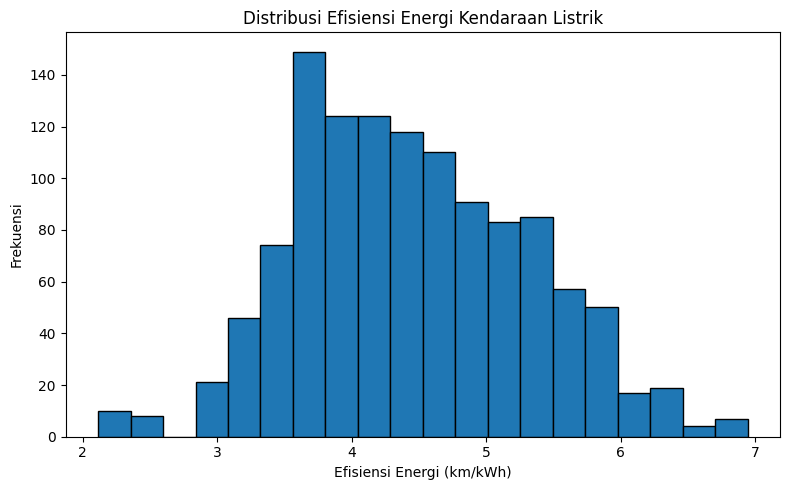

In [13]:

import pandas as pd
import matplotlib.pyplot as plt

# Memuat dataset hasil cleaning dari GitHub
url_clean = "https://raw.githubusercontent.com/leirisayajnakirana/Tugas-Besar-Analitika-Data/main/ev_energy_efficiency_clean.csv"

df_clean = pd.read_csv(url_clean)

# Memeriksa ukuran dan tipe data
print("Ukuran dataset:", df_clean.shape)
print("\nTipe data setiap kolom:")
print(df_clean.dtypes)

# Statistik deskriptif untuk variabel numerik
print("\nStatistik deskriptif:")
display(df_clean.describe())

# Memeriksa kembali distribusi target
plt.figure(figsize=(8, 5))
plt.hist(
    df_clean["Energy Efficiency (km/kWh)"],
    bins=20,
    edgecolor="black"
)
plt.title("Distribusi Efisiensi Energi Kendaraan Listrik")
plt.xlabel("Efisiensi Energi (km/kWh)")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()


## 2.2 Distribusi Produsen dan Kelas Kendaraan

10 Produsen dengan jumlah data terbanyak:


,Produsen,Jumlah Kendaraan
0,Tesla,184
1,Rivian,160
2,BMW,117
3,Ford,65
4,Audi,61
5,Porsche,56
6,Mercedes-Benz,54
7,Kia,50
8,Hyundai,48
9,Chevrolet,46



Jumlah data berdasarkan kelas kendaraan:


,Kelas Kendaraan,Jumlah Kendaraan
0,Sport utility vehicle: Standard,311
1,Sport utility vehicle: Small,236
2,Full-size,167
3,Pickup truck: Standard,129
4,Mid-size,128
5,Compact,93
6,Station wagon: Small,60
7,Subcompact,50
8,Two-seater,12
9,Station wagon: Mid-size,4


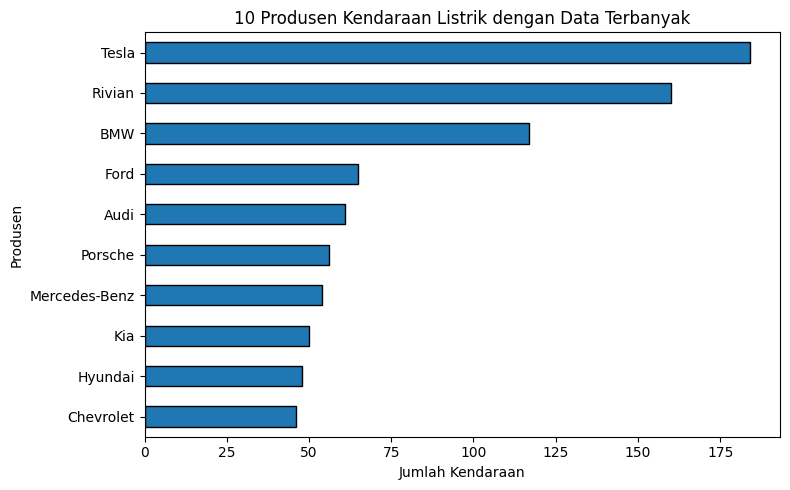

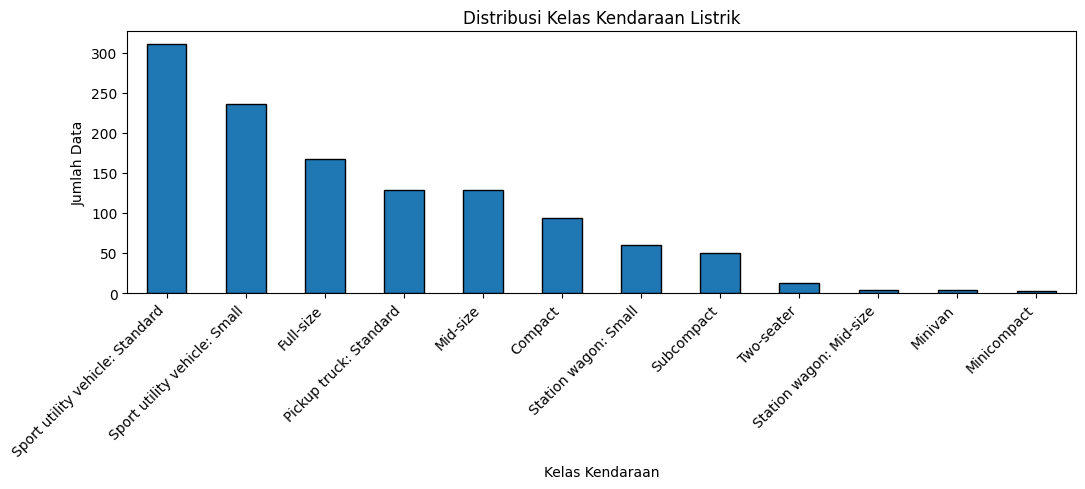

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Jumlah data berdasarkan produsen kendaraan
print("10 Produsen dengan jumlah data terbanyak:")
display(
    df_clean["Make"]
    .value_counts()
    .head(10)
    .rename_axis("Produsen")
    .reset_index(name="Jumlah Kendaraan")
)

# 2. Jumlah data berdasarkan kelas kendaraan
print("\nJumlah data berdasarkan kelas kendaraan:")
display(
    df_clean["Vehicle class"]
    .value_counts()
    .rename_axis("Kelas Kendaraan")
    .reset_index(name="Jumlah Kendaraan")
)

# 3. Visualisasi 10 produsen dengan data terbanyak
df_clean["Make"].value_counts().head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    edgecolor="black"
)

plt.title("10 Produsen Kendaraan Listrik dengan Data Terbanyak")
plt.xlabel("Jumlah Kendaraan")
plt.ylabel("Produsen")
plt.tight_layout()
plt.show()

# 4. Visualisasi distribusi kelas kendaraan
df_clean["Vehicle class"].value_counts().plot(
    kind="bar",
    figsize=(11, 5),
    edgecolor="black"
)

plt.title("Distribusi Kelas Kendaraan Listrik")
plt.xlabel("Kelas Kendaraan")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 2.3 Analisis Korelasi Antarvariabel

Matriks korelasi:


,Model year,Motor (kW),Recharge time (h),Energy Efficiency (km/kWh)
Model year,1.000,0.239,0.252,-0.301
Motor (kW),0.239,1.000,0.631,-0.462
Recharge time (h),0.252,0.631,1.000,-0.473
Energy Efficiency (km/kWh),-0.301,-0.462,-0.473,1.000


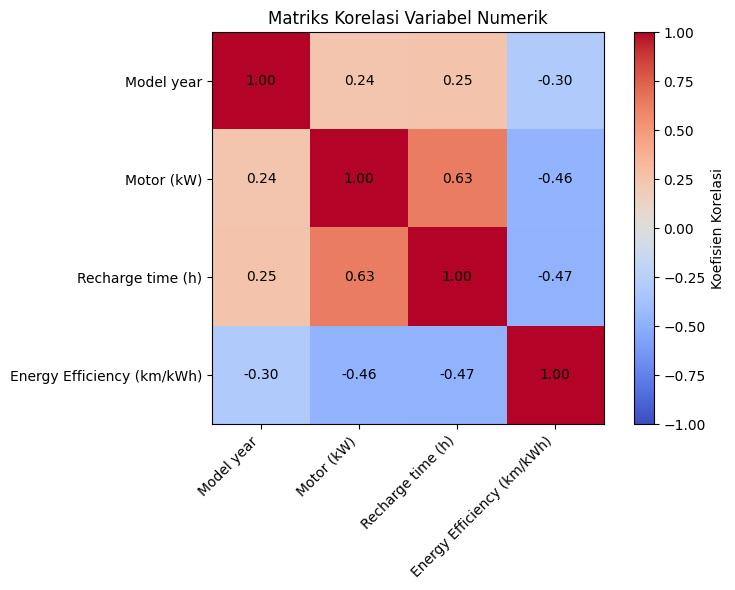

In [15]:

# Memilih variabel numerik
kolom_numerik = [
    "Model year",
    "Motor (kW)",
    "Recharge time (h)",
    "Energy Efficiency (km/kWh)"
]

# Menghitung korelasi antarvariabel numerik
korelasi = df_clean[kolom_numerik].corr()

print("Matriks korelasi:")
display(korelasi.round(3))

# Visualisasi matriks korelasi
plt.figure(figsize=(8, 6))

plt.imshow(korelasi, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="Koefisien Korelasi")

plt.xticks(
    range(len(kolom_numerik)),
    kolom_numerik,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(kolom_numerik)), kolom_numerik)

for i in range(len(kolom_numerik)):
    for j in range(len(kolom_numerik)):
        plt.text(
            j, i, f"{korelasi.iloc[i, j]:.2f}",
            ha="center", va="center"
        )

plt.title("Matriks Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()


## 2.4 Hubungan Variabel Prediktor dengan Efisiensi Energi

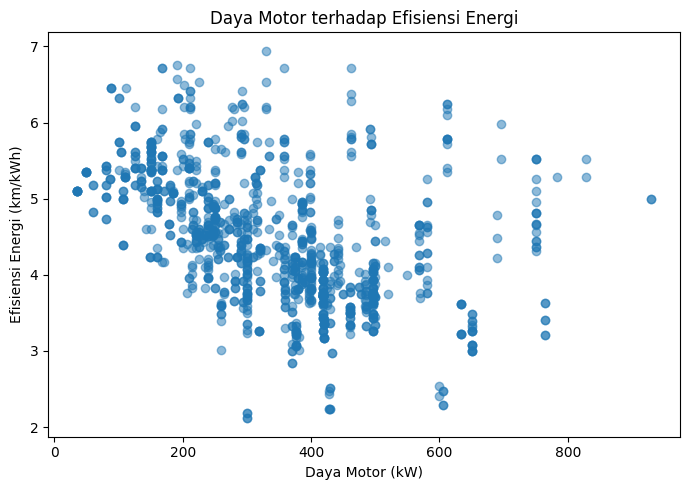

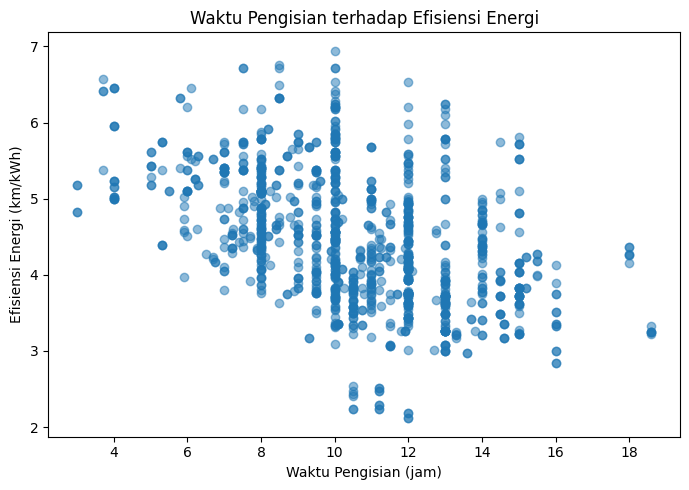

In [16]:
import matplotlib.pyplot as plt

# Hubungan daya motor dengan efisiensi energi
plt.figure(figsize=(7, 5))
plt.scatter(
    df_clean["Motor (kW)"],
    df_clean["Energy Efficiency (km/kWh)"],
    alpha=0.5
)
plt.title("Daya Motor terhadap Efisiensi Energi")
plt.xlabel("Daya Motor (kW)")
plt.ylabel("Efisiensi Energi (km/kWh)")
plt.tight_layout()
plt.show()

# Hubungan waktu pengisian dengan efisiensi energi
plt.figure(figsize=(7, 5))
plt.scatter(
    df_clean["Recharge time (h)"],
    df_clean["Energy Efficiency (km/kWh)"],
    alpha=0.5
)
plt.title("Waktu Pengisian terhadap Efisiensi Energi")
plt.xlabel("Waktu Pengisian (jam)")
plt.ylabel("Efisiensi Energi (km/kWh)")
plt.tight_layout()
plt.show()

## 2.5 Distribusi Data dan Identifikasi Kandidat Pencilan

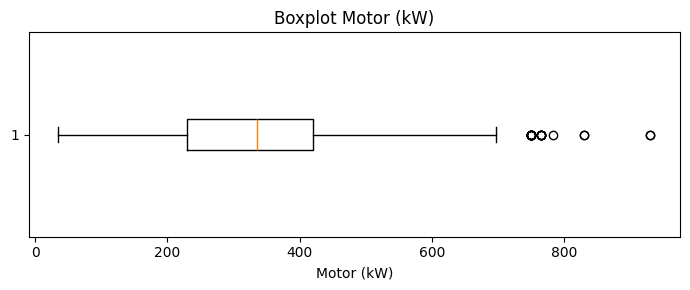

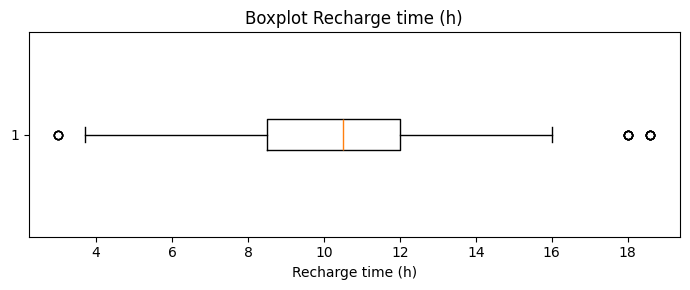

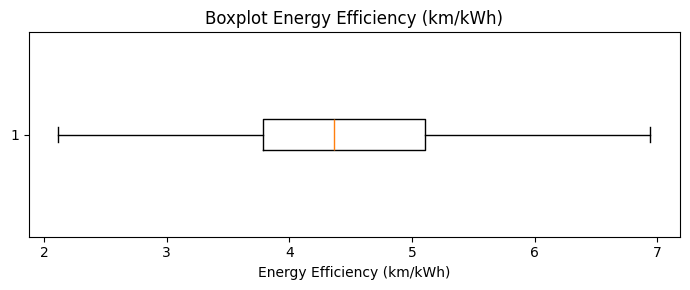

In [17]:

# Membandingkan sebaran variabel numerik dan mendeteksi kandidat outlier
kolom_boxplot = [
    "Motor (kW)",
    "Recharge time (h)",
    "Energy Efficiency (km/kWh)"
]

for kolom in kolom_boxplot:
    plt.figure(figsize=(7, 3))
    plt.boxplot(df_clean[kolom].dropna(), vert=False)
    plt.title(f"Boxplot {kolom}")
    plt.xlabel(kolom)
    plt.tight_layout()
    plt.show()


# 3. Pemodelan Multiple Linear Regression


## 3.1 Data Preparation

### A. Penentuan Variabel Independen dan Dependen
- Variabel dependen (Y) = Energy Efficiency (km/kWh)
- Variabel independen (X) = Model year, Make, Model, Vehicle class, Motor (kW), dan Recharge time (h)

In [18]:

# Menentukan variabel independen (X) dan dependen (y)

fitur = [
    "Model year",
    "Make",
    "Model",
    "Vehicle class",
    "Motor (kW)",
    "Recharge time (h)"
]

target = "Energy Efficiency (km/kWh)"

X = df_clean[fitur].copy()
y = df_clean[target].copy()

# Memeriksa ukuran variabel
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

# Memeriksa lima data pertama
display(X.head())
display(y.head())


Ukuran X: (1197, 6)
Ukuran y: (1197,)


,Model year,Make,Model,Vehicle class,Motor (kW),Recharge time (h)
0,2012,Mitsubishi,i-MiEV,Subcompact,49,7.0
1,2012,Nissan,LEAF,Mid-size,80,7.0
2,2013,Ford,Focus Electric,Compact,107,4.0
3,2013,Mitsubishi,i-MiEV,Subcompact,49,7.0
4,2013,Nissan,LEAF,Mid-size,80,7.0


0    5.347594
1    4.739336
2    5.000000
3    5.347594
4    4.739336
Name: Energy Efficiency (km/kWh), dtype: float64


### B. Pembagian Dataset

In [32]:

# Memisahkan variabel prediktor dan target
kolom_target = "Energy Efficiency (km/kWh)"

X = df_clean.drop(columns=[kolom_target])
y = df_clean[kolom_target]

print("Dimensi X:", X.shape)
print("Dimensi y:", y.shape)

# Mengimpor fungsi pembagian dataset
from sklearn.model_selection import train_test_split

# Tahap 1: Memisahkan 30% data untuk validation dan testing
X_train, X_sisa, y_train, y_sisa = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Tahap 2: Membagi sisa data menjadi validation 15% dan testing 15%
X_val, X_test, y_val, y_test = train_test_split(
    X_sisa,
    y_sisa,
    test_size=0.50,
    random_state=42
)

# Memeriksa ukuran setiap subset
print("Jumlah data awal:", len(X))
print(f"Training set   : {len(X_train)} data ({len(X_train)/len(X)*100:.2f}%)")
print(f"Validation set : {len(X_val)} data ({len(X_val)/len(X)*100:.2f}%)")
print(f"Testing set    : {len(X_test)} data ({len(X_test)/len(X)*100:.2f}%)")

Dimensi X: (1197, 6)
Dimensi y: (1197,)
Jumlah data awal: 1197
Training set   : 837 data (69.92%)
Validation set : 180 data (15.04%)
Testing set    : 180 data (15.04%)


### C. Encoding Variabel Kategorikal


In [33]:
# Menjalankan encoding pada data training
X_train_encoded = preprocessor.fit_transform(X_train)

# Menerapkan encoding pada data validation dan testing
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)

# Memeriksa dimensi hasil encoding
print("Dimensi training setelah encoding:", X_train_encoded.shape)
print("Dimensi validation setelah encoding:", X_val_encoded.shape)
print("Dimensi testing setelah encoding:", X_test_encoded.shape)

Dimensi training setelah encoding: (837, 535)
Dimensi validation setelah encoding: (180, 535)
Dimensi testing setelah encoding: (180, 535)


## 3.2 Pembangunan Model Multiple Linear Regression

In [36]:
# Mengimpor algoritma Multiple Linear Regression
from sklearn.linear_model import LinearRegression

# Inisialisasi model
model_mlr = LinearRegression()

# Melatih model menggunakan data training
model_mlr.fit(X_train_encoded, y_train)

print("Model Multiple Linear Regression berhasil dilatih.")

Model Multiple Linear Regression berhasil dilatih.



## 3.3 Evaluasi Model pada Validation Set


In [40]:
# Mengimpor metrik evaluasi
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Melakukan prediksi pada validation set
y_val_pred = model_mlr.predict(X_val_encoded)

# Menghitung metrik evaluasi
mae_val = mean_absolute_error(y_val, y_val_pred)
mse_val = mean_squared_error(y_val, y_val_pred)
rmse_val = np.sqrt(mse_val)
r2_val = r2_score(y_val, y_val_pred)

# Menampilkan hasil evaluasi
print("Evaluasi Multiple Linear Regression - Validation Set")
print(f"MAE  : {mae_val:.4f}")
print(f"MSE  : {mse_val:.4f}")
print(f"RMSE : {rmse_val:.4f}")
print(f"R²   : {r2_val:.4f}")

Evaluasi Multiple Linear Regression - Validation Set
MAE  : 0.2630
MSE  : 0.1643
RMSE : 0.4053
R²   : 0.7567


## 3.4 Evaluasi Model pada Test Set

In [41]:
# Melakukan prediksi pada test set
y_test_pred = model_mlr.predict(X_test_encoded)

# Menghitung metrik evaluasi
mae_test = mean_absolute_error(y_test, y_test_pred)
mse_test = mean_squared_error(y_test, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test, y_test_pred)

# Menampilkan hasil evaluasi
print("Evaluasi Multiple Linear Regression - Test Set")
print(f"MAE  : {mae_test:.4f}")
print(f"MSE  : {mse_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"R²   : {r2_test:.4f}")

Evaluasi Multiple Linear Regression - Test Set
MAE  : 0.2846
MSE  : 0.2289
RMSE : 0.4784
R²   : 0.6985


## 3.5 Visualisasi Hasil Prediksi dan Nilai Aktual

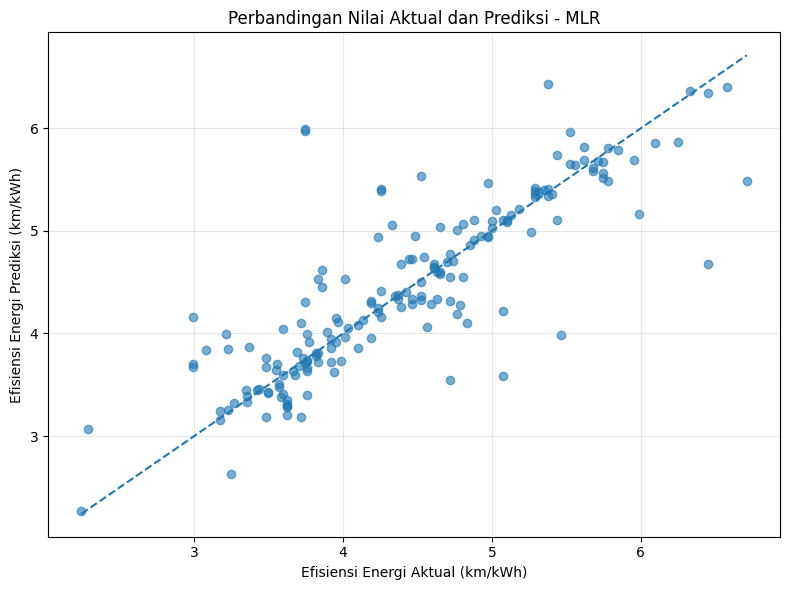

In [43]:

import matplotlib.pyplot as plt

# Membuat scatter plot nilai aktual dan prediksi
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.6
)

# Garis prediksi ideal: nilai prediksi = nilai aktual
nilai_min = min(y_test.min(), y_test_pred.min())
nilai_max = max(y_test.max(), y_test_pred.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    linestyle="--"
)

plt.xlabel("Efisiensi Energi Aktual (km/kWh)")
plt.ylabel("Efisiensi Energi Prediksi (km/kWh)")
plt.title("Perbandingan Nilai Aktual dan Prediksi - MLR")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3.6 Analisis Residual

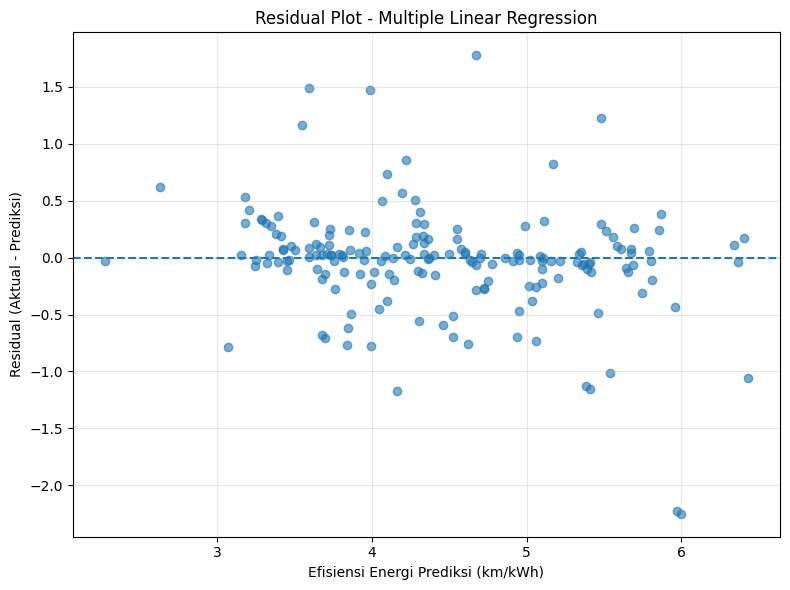

In [26]:

import matplotlib.pyplot as plt

# Menghitung residual pada test set
residual = y_test - y_test_pred

# Membuat residual plot
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred,
    residual,
    alpha=0.6
)

# Garis residual nol
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Efisiensi Energi Prediksi (km/kWh)")
plt.ylabel("Residual (Aktual - Prediksi)")
plt.title("Residual Plot - Multiple Linear Regression")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 3.7 Analisis Distribusi dan Uji Normalitas Residual

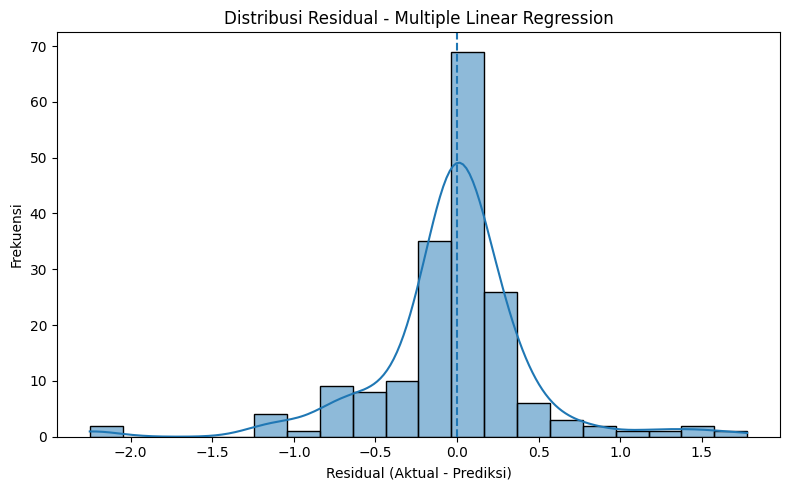

Uji Normalitas Residual - Shapiro-Wilk
Statistik : 0.8541
P-value   : 0.0000
Kesimpulan: Residual menunjukkan penyimpangan signifikan dari distribusi normal.


In [27]:

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro

# Menghitung residual pada test set
residual = y_test - y_test_pred

# Histogram residual
plt.figure(figsize=(8, 5))
sns.histplot(residual, bins=20, kde=True)
plt.axvline(0, linestyle="--")
plt.xlabel("Residual (Aktual - Prediksi)")
plt.ylabel("Frekuensi")
plt.title("Distribusi Residual - Multiple Linear Regression")
plt.tight_layout()
plt.show()

# Uji normalitas Shapiro-Wilk
statistik, p_value = shapiro(residual)

print("Uji Normalitas Residual - Shapiro-Wilk")
print(f"Statistik : {statistik:.4f}")
print(f"P-value   : {p_value:.4f}")

alpha = 0.05

if p_value > alpha:
    print("Kesimpulan: Tidak terdapat bukti yang cukup untuk menolak normalitas residual.")
else:
    print("Kesimpulan: Residual menunjukkan penyimpangan signifikan dari distribusi normal.")


## 3.8 Uji Heteroskedastisitas

In [50]:
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

# 1. Menghitung prediksi pada training set
y_train_pred = model_mlr.predict(X_train_encoded)

# 2. Menghitung residual training
residual_train = np.asarray(y_train) - y_train_pred

# 3. Memilih variabel numerik sebagai variabel penjelas
kolom_numerik = [
    "Model year",
    "Motor (kW)",
    "Recharge time (h)"
]

X_bp = X_train[kolom_numerik].astype(float)

# 4. Menambahkan konstanta
X_bp = sm.add_constant(X_bp, has_constant="add")

# 5. Melakukan uji Breusch-Pagan
hasil_bp = het_breuschpagan(
    residual_train,
    X_bp
)

lm_stat, lm_pvalue, f_stat, f_pvalue = hasil_bp

# 6. Menampilkan hasil pengujian
print("Uji Breusch-Pagan pada Training Set")
print(f"LM Statistic : {lm_stat:.4f}")
print(f"LM P-value   : {lm_pvalue:.6f}")
print(f"F Statistic  : {f_stat:.4f}")
print(f"F P-value    : {f_pvalue:.6f}")

# 7. Interpretasi hasil
if lm_pvalue < 0.05:
    print("Kesimpulan: Terdapat indikasi heteroskedastisitas.")
else:
    print(
        "Kesimpulan: Belum terdapat bukti yang cukup "
        "untuk menyatakan adanya heteroskedastisitas."
    )

Uji Breusch-Pagan pada Training Set
LM Statistic : 11.7024
LM P-value   : 0.008475
F Statistic  : 3.9372
F P-value    : 0.008346
Kesimpulan: Terdapat indikasi heteroskedastisitas.


## 3.9 Pemeriksaan Multikolinearitas pada Variabel Numerik

In [53]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Ambil variabel numerik dari data training
kolom_numerik = [
    "Model year",
    "Motor (kW)",
    "Recharge time (h)"
]

X_vif = X_train[kolom_numerik].astype(float)

# Tambahkan konstanta
X_vif_const = sm.add_constant(X_vif, has_constant="add")

# Hitung VIF
hasil_vif = pd.DataFrame({
    "Variabel": X_vif_const.columns,
    "VIF": [
        variance_inflation_factor(X_vif_const.values, i)
        for i in range(X_vif_const.shape[1])
    ]
})

# Hilangkan konstanta
hasil_vif = hasil_vif[hasil_vif["Variabel"] != "const"]

print("Hasil Uji Multikolinearitas (VIF)")
display(hasil_vif.round(4))

Hasil Uji Multikolinearitas (VIF)


,Variabel,VIF
1,Model year,1.0878
2,Motor (kW),1.6727
3,Recharge time (h),1.6738


## 3.10 Interpretasi Koefisien Regresi

In [56]:
import pandas as pd

# Ambil koefisien dari model MLR
koefisien = model_mlr.coef_

# Ambil nama fitur setelah preprocessing
nama_fitur = preprocessor.get_feature_names_out()

tabel_koefisien = pd.DataFrame({
    "Fitur": nama_fitur,
    "Koefisien": koefisien
})

# Pilih tiga fitur numerik
fitur_numerik = [
    "Model year",
    "Motor (kW)",
    "Recharge time (h)"
]

hasil_numerik = tabel_koefisien[
    tabel_koefisien["Fitur"].apply(
        lambda x: any(x.endswith(f) for f in fitur_numerik)
    )
]

display(hasil_numerik.round(4))

,Fitur,Koefisien
532,numerik__Model year,0.0253
533,numerik__Motor (kW),0.0021
534,numerik__Recharge time (h),0.0025
